# Numerical data distributions

One dashboard for all numerical columns in `hcv_median_imputed.csv` (608 patients). Axes use the original scales. `cat_num` is a diagnosis code, so it is displayed as a count bar chart rather than a histogram.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import normaltest, shapiro

# Read the saved dataset without changing it.
df = pd.read_csv("hcv_median_imputed.csv")
numeric_columns = df.select_dtypes(include="number").columns


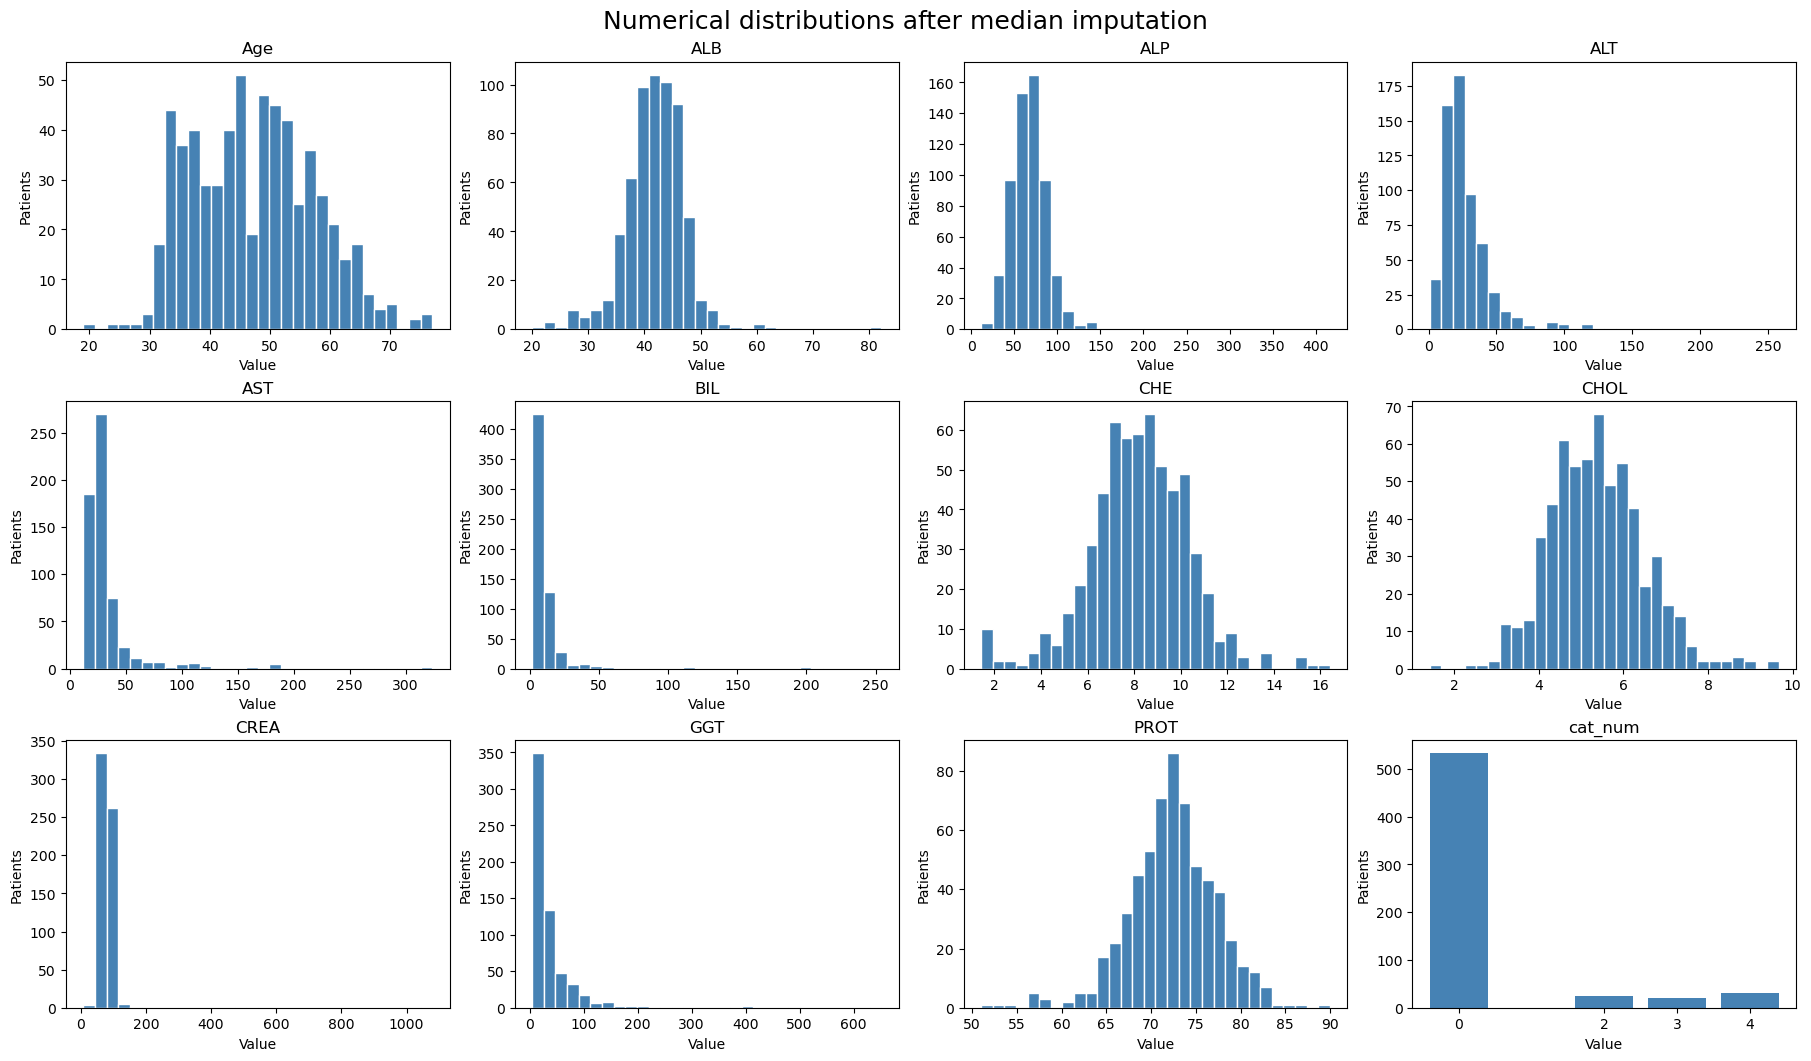

In [2]:
# Four plots per row keep all numerical columns on one dashboard.
rows = (len(numeric_columns) + 3) // 4
fig, axes = plt.subplots(
    rows, 4, figsize=(18, rows * 3.5), constrained_layout=True,
)

for ax, column in zip(axes.flat, numeric_columns):
    if column == "cat_num":
        # Diagnosis codes are categories, not continuous measurements.
        counts = df[column].value_counts().sort_index()
        ax.bar(counts.index, counts.values, color="steelblue")
        ax.set_xticks(counts.index)
    else:
        ax.hist(df[column], bins=30, color="steelblue", edgecolor="white")

    ax.set_title(column)
    ax.set_xlabel("Value")
    ax.set_ylabel("Patients")

# Hide any unused panels if the number of columns changes.
for ax in list(axes.flat)[len(numeric_columns):]:
    ax.set_visible(False)

fig.suptitle("Numerical distributions after median imputation", fontsize=18)
plt.show()


## Normality tests

Shapiro–Wilk and D’Agostino–Pearson test the null hypothesis of a normal distribution. Bonferroni-adjusted p-values account for both tests across all 11 numerical measurements. At 0.05, either significant adjusted test is evidence against normality. **A non-significant result does not prove normality.**

These tests use the median-imputed dataset pooled across all diagnoses. Median filling creates repeated values, and combining diagnostic groups can alter the distribution. These are descriptive checks, not a rule requiring transformation. Logistic Regression and Random Forest do not require normally distributed predictors.

In [3]:
# The diagnosis code is categorical, so do not test its normality.
measurement_columns = numeric_columns.drop("cat_num", errors="ignore")
normality_rows = []

for column in measurement_columns:
    values = df[column].dropna()
    shapiro_result = shapiro(values)
    dagostino_result = normaltest(values)
    normality_rows.append({
        "Column": column,
        "N": len(values),
        "Shapiro W": shapiro_result.statistic,
        "Shapiro p": shapiro_result.pvalue,
        "DAgostino K2": dagostino_result.statistic,
        "DAgostino p": dagostino_result.pvalue,
    })

normality_results = pd.DataFrame(normality_rows).set_index("Column")

# Correct across both tests and all measurements (22 comparisons here).
number_of_tests = len(measurement_columns) * 2
normality_results["Shapiro adjusted p"] = (
    normality_results["Shapiro p"] * number_of_tests
).clip(upper=1)
normality_results["DAgostino adjusted p"] = (
    normality_results["DAgostino p"] * number_of_tests
).clip(upper=1)

normality_results["Interpretation"] = "Normality not rejected"
rejected = (
    (normality_results["Shapiro adjusted p"] < 0.05)
    | (normality_results["DAgostino adjusted p"] < 0.05)
)
normality_results.loc[rejected, "Interpretation"] = "Normality rejected"
normality_results


,N,Shapiro W,Shapiro p,DAgostino K2,DAgostino p,Shapiro adjusted p,DAgostino adjusted p,Interpretation
Column,,,,,,,,
Age,608,0.984,3.365e-06,13.24,0.001333,7.402e-05,0.02933,Normality rejected
ALB,608,0.9429,1.561e-14,95.62,1.724e-21,3.435e-13,3.793e-20,Normality rejected
ALP,608,0.7658,1.588e-28,682.6,5.815e-149,3.493e-27,1.279e-147,Normality rejected
ALT,608,0.6812,2.979e-32,578,3.029e-126,6.554e-31,6.664e-125,Normality rejected
AST,608,0.4586,3.241e-39,654.2,8.94e-143,7.13e-38,1.967e-141,Normality rejected
BIL,608,0.3123,1.355e-42,901.1,2.171e-196,2.981e-41,4.776e-195,Normality rejected
CHE,608,0.9795,1.608e-07,22.88,1.078e-05,3.537e-06,0.0002372,Normality rejected
CHOL,608,0.9882,8.307e-05,24.98,3.764e-06,0.001828,8.28e-05,Normality rejected
CREA,608,0.2345,3.727e-44,1251,2.066e-272,8.199e-43,4.544e-271,Normality rejected


## Findings

**Normality not rejected:** None.

**Normality rejected:** Age, ALB, ALP, ALT, AST, BIL, CHE, CHOL, CREA, GGT, PROT.

Use the histograms above to judge the shape and severity of departures, rather than interpreting p-values alone.